Device: cpu | GPU: CPU


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (12 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step 10/63 | loss=0.7274
step 20/63 | loss=0.6219
step 30/63 | loss=0.5937
step 40/63 | loss=0.6401
step 50/63 | loss=0.4845
step 60/63 | loss=0.3430
step 63/63 | loss=0.5097

=== Accuracy by confidence group ===
  confidence_group  samples accuracy  errors mean_confidence
       Low (<0.60)       37   43.24%      21          0.5586
Medium (0.60–0.80)      116   69.83%      35          0.7249
     High (>=0.80)      347   91.93%      28          0.8561

Overall accuracy: 0.8320
Incorrect predictions with confidence >= 0.80: 28
Training time: 934.1s


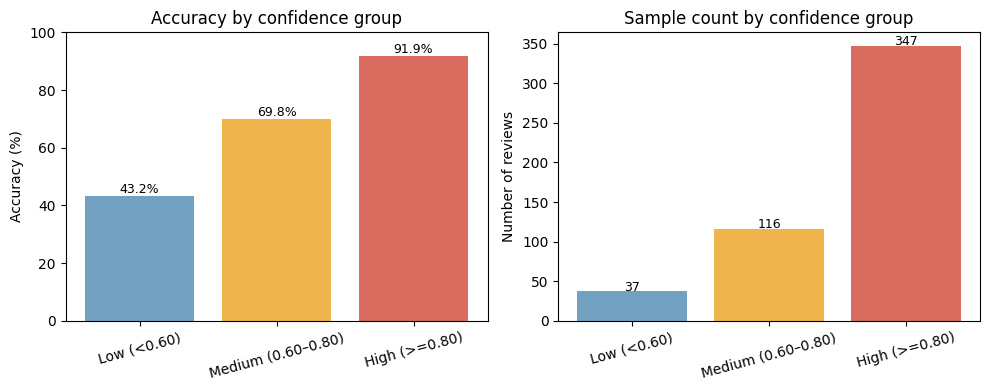

Saved plot: confidence_analysis.png

=== Top 5 confident wrong predictions ===
index=378 | true=positive | pred=negative | confidence=0.8931
The dead spots and picture-postcard superficiality of "Out of Africa" just about buried any interest I might have had to read Isak Dinesen. So when my brother bought me "Babette's Feast," and knowing it was based on a Dinesen story, I didn't exactly race to the VCR. But as the titles rolled, it became clear that this was no ordinary movie. Jutland (where it's set) is not Africa; the chill mist that collects on the camera shots is not inviting. The cold, forbidding sea; the heavy, gray clouds; th

index=341 | true=positive | pred=negative | confidence=0.8917
I rank OPERA as one of the better Argento films. Plot holes and inconsistencies? Sure, but I don't think they impair this film as much as many other reviewers seem to. A lot of elements that are in many of Argento's films are kinda "off-the-wall", but that's part of the draw of his films... Sho

In [ ]:
%pip -q install datasets transformers scikit-learn matplotlib

import random, time, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
from torch.utils.data import DataLoader

# Bài 21 — Confidence Analysis trên IMDb
# Tái lập cấu hình Bài 19 để tạo xác suất dự đoán; GPU tự dùng nếu có, nếu không dùng CPU.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

# IMDb: 1,000 mẫu train cân bằng, 500 mẫu test cân bằng như Bài 19.
imdb = load_dataset('stanfordnlp/imdb')
def balanced_sample(ds, n, seed):
    n_each = n // 2
    labels = np.asarray(ds['label'])
    rng = np.random.default_rng(seed)
    chosen = []
    for label in (0, 1):
        idx = np.flatnonzero(labels == label)
        rng.shuffle(idx)
        chosen.extend(idx[:n_each].tolist())
    rng.shuffle(chosen)
    return ds.select(chosen)

train_ds = balanced_sample(imdb['train'], 1000, SEED)
test_ds = balanced_sample(imdb['test'], 500, SEED + 1)
model_name = 'bert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)
MAX_LENGTH = 128
def tokenize(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH)
train_ds = train_ds.map(tokenize, batched=True, remove_columns=[c for c in train_ds.column_names if c != 'label'])
test_ds = test_ds.map(tokenize, batched=True, remove_columns=[c for c in test_ds.column_names if c != 'label'])
for ds in (train_ds, test_ds):
    ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8 if torch.cuda.is_available() else None)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, collate_fn=collator)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, collate_fn=collator)

# Fine-tune một epoch, giữ cấu hình và seed giống Bài 19.
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
start = time.time(); model.train()
for step, batch in enumerate(train_loader, start=1):
    batch = {k: v.to(device) for k, v in batch.items()}
    loss = model(**batch).loss
    loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step(); optimizer.zero_grad(set_to_none=True)
    if step % 10 == 0 or step == len(train_loader):
        print(f'step {step}/{len(train_loader)} | loss={loss.item():.4f}')
train_seconds = time.time() - start

# Softmax xác suất theo lớp; confidence = xác suất cao nhất.
model.eval(); y_true, y_pred, confidence, prob_negative, prob_positive = [], [], [], [], []
with torch.no_grad():
    for batch in test_loader:
        labels = batch.pop('labels').cpu().numpy()
        inputs = {k: v.to(device) for k, v in batch.items()}
        probs = torch.softmax(model(**inputs).logits, dim=-1).cpu().numpy()
        preds = probs.argmax(axis=1)
        y_true.extend(labels.tolist()); y_pred.extend(preds.tolist())
        confidence.extend(probs.max(axis=1).tolist())
        prob_negative.extend(probs[:, 0].tolist()); prob_positive.extend(probs[:, 1].tolist())

results = pd.DataFrame({
    'true_label': y_true, 'predicted_label': y_pred,
    'prob_negative': prob_negative, 'prob_positive': prob_positive,
    'confidence': confidence
})
results['correct'] = results['true_label'] == results['predicted_label']
# Ngưỡng phân nhóm do thí nghiệm đặt trước: low < .60, medium [.60, .80), high >= .80.
results['confidence_group'] = pd.cut(
    results['confidence'], bins=[0.0, 0.60, 0.80, 1.000001],
    labels=['Low (<0.60)', 'Medium (0.60–0.80)', 'High (>=0.80)'],
    include_lowest=True, right=False
)
summary = results.groupby('confidence_group', observed=False).agg(
    samples=('correct', 'size'),
    accuracy=('correct', 'mean'),
    errors=('correct', lambda s: int((~s).sum())),
    mean_confidence=('confidence', 'mean')
).reset_index()
summary['accuracy'] = summary['accuracy'] * 100
print('\n=== Accuracy by confidence group ===')
print(summary.to_string(index=False, formatters={
    'accuracy': lambda x: f'{x:.2f}%',
    'mean_confidence': lambda x: f'{x:.4f}'
}))
print(f'\nOverall accuracy: {results["correct"].mean():.4f}')
print('Incorrect predictions with confidence >= 0.80:', int(((~results['correct']) & (results['confidence'] >= 0.80)).sum()))
print(f'Training time: {train_seconds:.1f}s')

# Biểu đồ accuracy và số mẫu cho từng nhóm; lưu PNG trong thư mục làm việc Colab.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = ['#72a0c1', '#f0b44d', '#d96b5f']
labels = summary['confidence_group'].astype(str).tolist()
axes[0].bar(labels, summary['accuracy'], color=colors)
axes[0].set_ylim(0, 100); axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Accuracy by confidence group')
for i, value in enumerate(summary['accuracy']):
    axes[0].text(i, value + 1, f'{value:.1f}%', ha='center', fontsize=9)
axes[1].bar(labels, summary['samples'], color=colors)
axes[1].set_ylabel('Number of reviews'); axes[1].set_title('Sample count by confidence group')
for i, value in enumerate(summary['samples']):
    axes[1].text(i, value + 1, str(value), ha='center', fontsize=9)
for ax in axes: ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig('confidence_analysis.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved plot: confidence_analysis.png')

# Xem các lỗi model tự tin nhất để kiểm tra confidence cao có đồng nghĩa prediction đúng không.
raw_test = balanced_sample(imdb['test'], 500, SEED + 1)
wrong = results.loc[~results['correct']].copy()
wrong['text'] = [raw_test[int(i)]['text'].replace('<br /><br />', ' ')[:500] for i in wrong.index]
print('\n=== Top 5 confident wrong predictions ===')
for _, row in wrong.sort_values('confidence', ascending=False).head(5).iterrows():
    true_name = 'positive' if row.true_label == 1 else 'negative'
    pred_name = 'positive' if row.predicted_label == 1 else 'negative'
    print(f'index={row.name} | true={true_name} | pred={pred_name} | confidence={row.confidence:.4f}')
    print(row.text + '\n')